# fsaverage native-column mapping QC

Publication-style single-panel figures; source data are not modified.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
from pathlib import Path
_available_fonts={f.name for f in font_manager.fontManager.ttflist}
_selected_font=('Arial' if 'Arial' in _available_fonts else 'Liberation Sans' if 'Liberation Sans' in _available_fonts else 'DejaVu Sans')
print('Using font:', _selected_font)
mpl.rcParams.update({'font.family':_selected_font,'font.size':7,'axes.labelsize':8,'xtick.labelsize':7,'ytick.labelsize':7,'legend.fontsize':7,'axes.linewidth':.8,'xtick.direction':'out','ytick.direction':'out','xtick.major.size':3,'ytick.major.size':3,'figure.facecolor':'white','savefig.facecolor':'white','savefig.dpi':1200,'pdf.fonttype':42,'svg.fonttype':'none'})
OKABE={'blue':'#0072B2','orange':'#E69F00','purple':'#CC79A7'}
WIDTH,HEIGHT=3.35,2.8
def save_figure(fig,stem):
    png=QC_ROOT/f'{stem}.png'; pdf=QC_ROOT/f'{stem}.pdf'; svg=QC_ROOT/f'{stem}.svg'
    fig.savefig(png,dpi=1200,bbox_inches='tight',pad_inches=0.03,facecolor='white')
    fig.savefig(pdf,bbox_inches='tight',pad_inches=0.03,facecolor='white')
    fig.savefig(svg,bbox_inches='tight',pad_inches=0.03,facecolor='white')
    mpl.rcParams['figure.dpi']=180
    display(fig)
    print(f'Saved: {png} ({png.stat().st_size/1024:.0f} KB)')
    plt.close(fig)

QC_ROOT=Path('/mnt/newStor/paros/paros_WORK/xintong/results/fsaverage_mapping_qc')
region_qc=pd.read_csv(QC_ROOT/'fsaverage_subject_region_mapping_qc.csv'); vertex_freq=pd.read_csv(QC_ROOT/'fsaverage_template_vertex_coverage_frequency.csv'); region_freq=pd.read_csv(QC_ROOT/'fsaverage_region_coverage_frequency_summary.csv'); failures=pd.read_csv(QC_ROOT/'fsaverage_mapping_failures.csv')
print(f'Subjects: {region_qc.subject_id.nunique():,}; rows: {len(region_qc):,}; failures: {len(failures):,}')
coverage_stats=region_qc.groupby('hemisphere').agg(coverage_pct=('regional_coverage_valid_pct','median'), theoretical_max_pct=('theoretical_max_coverage_after_cleaning_pct','median'), efficiency_pct=('coverage_efficiency_after_cleaning_pct','median')).reindex(['lh','rh'])
print('Median coverage statistics (%)')
display(coverage_stats.round(2))
print(f'Overall median coverage: {region_qc.regional_coverage_valid_pct.median():.2f}%')
region_accuracy_stats=region_qc.groupby(['hemisphere','region']).region_label_agreement_pct.agg(median='median',p25=lambda x:x.quantile(.25),p75=lambda x:x.quantile(.75)).reset_index().sort_values(['hemisphere','median'])
print('Region-label accuracy by cortical region (%)')
display(region_accuracy_stats.round(2))


Using font: DejaVu Sans
Subjects: 297; rows: 20,196; failures: 0
Median coverage statistics (%)


,coverage_pct,theoretical_max_pct,efficiency_pct
hemisphere,,,
lh,65.57,78.07,84.35
rh,65.65,77.92,84.51


Overall median coverage: 65.60%
Region-label accuracy by cortical region (%)


,hemisphere,region,median,p25,p75
10,lh,isthmuscingulate,75.28,73.30,77.73
9,lh,insula,83.38,79.57,85.52
14,lh,medialorbitofrontal,84.08,81.93,87.99
5,lh,frontalpole,84.45,82.46,86.42
19,lh,parsorbitalis,85.16,83.97,86.25
...,...,...,...,...,...
62,rh,superiorfrontal,96.38,96.15,96.59
61,rh,rostralmiddlefrontal,96.65,96.42,96.94
50,rh,paracentral,96.79,96.39,97.14
58,rh,precentral,97.64,97.42,97.88


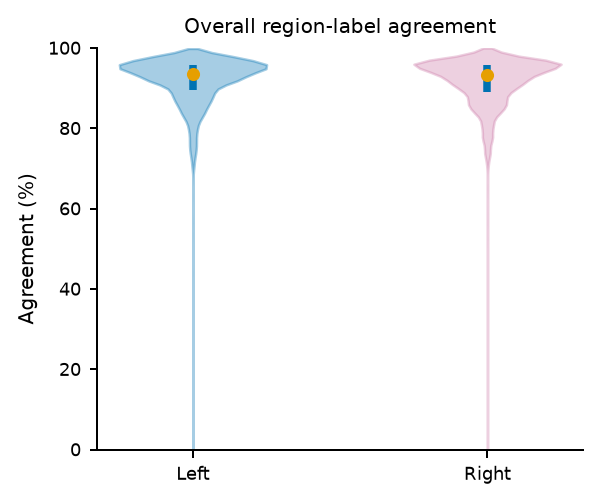

Saved: /mnt/newStor/paros/paros_WORK/xintong/results/fsaverage_mapping_qc/02b_overall_region_label_agreement.png (257 KB)


In [ ]:
groups=[region_qc.loc[region_qc.hemisphere.eq(h),'region_label_agreement_pct'].dropna().to_numpy() for h in ('lh','rh')]
fig,ax=plt.subplots(figsize=(WIDTH,HEIGHT))
parts=ax.violinplot(groups,positions=[1,2],showmeans=False,showmedians=False,showextrema=False)
for body,color in zip(parts['bodies'],[OKABE['blue'],OKABE['purple']]):
    body.set_facecolor(color); body.set_edgecolor(color); body.set_alpha(.35)
for i,values in enumerate(groups,1):
    q1,med,q3=np.percentile(values,[25,50,75])
    ax.vlines(i,q1,q3,color=OKABE['blue'],linewidth=3)
    ax.scatter(i,med,color=OKABE['orange'],s=18,zorder=3)
ax.set_title('Overall region-label agreement',fontsize=8,pad=6)
ax.set_ylabel('Agreement (%)'); ax.set_xticks([1,2]); ax.set_xticklabels(['Left','Right'])
ax.set_ylim(0,100); ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); save_figure(fig,'02b_overall_region_label_agreement')

In [ ]:
multiplicity_cols=['multiplicity_2_vertices','multiplicity_3_vertices','multiplicity_4_vertices','multiplicity_5_vertices','multiplicity_6plus_vertices']
if not set(multiplicity_cols).issubset(region_qc.columns):
    print('Conflict multiplicity 4/5/>=6 fields are not available in this QC table.')
else:
    multiplicity_labels=['2','3','4','5','>=6']
    multiplicity_counts=region_qc[multiplicity_cols].sum().astype(float)
    multiplicity_pct=100*multiplicity_counts/multiplicity_counts.sum()
    display(pd.DataFrame({'multiplicity':multiplicity_labels,'target_vertices':multiplicity_counts.astype(int).to_numpy(),'percentage':multiplicity_pct.to_numpy()}))
    fig,ax=plt.subplots(figsize=(WIDTH,HEIGHT))
    bars=ax.bar(multiplicity_labels,multiplicity_pct.to_numpy(),color=[OKABE['blue'],OKABE['purple'],OKABE['orange'],'#56B4E9','#009E73'])
    ax.set_title('fsaverage6 conflict multiplicity',fontsize=8,pad=6)
    ax.set_xlabel('Native columns mapped to one target vertex'); ax.set_ylabel('Percentage of conflict vertices (%)'); ax.set_ylim(0, max(100, multiplicity_pct.max()*1.2))
    ax.spines[['top','right']].set_visible(False)
    for bar,value in zip(bars,multiplicity_pct.to_numpy()): ax.text(bar.get_x()+bar.get_width()/2,value+1,f'{value:.1f}%',ha='center',va='bottom',fontsize=7)
    fig.tight_layout(); save_figure(fig,'02c_conflict_multiplicity')

Conflict multiplicity 4/5/>=6 fields are not available in this QC table.


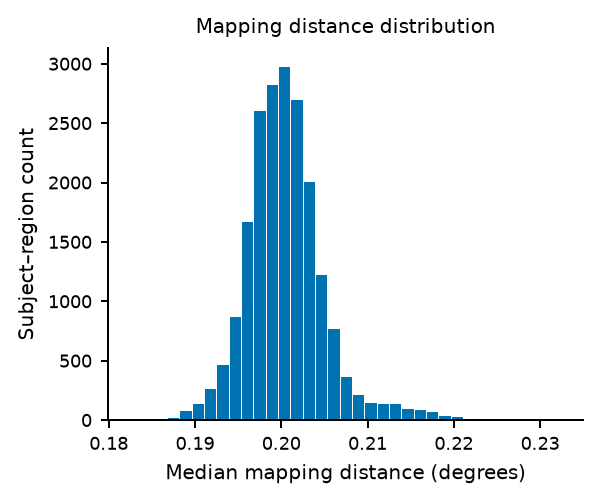

Saved: /mnt/newStor/paros/paros_WORK/xintong/results/fsaverage_mapping_qc/01_mapping_distance_distribution.png (224 KB)


In [ ]:
x=region_qc.mapping_distance_median_deg.dropna(); fig,ax=plt.subplots(figsize=(WIDTH,HEIGHT)); ax.hist(x,bins=35,color=OKABE['blue'],edgecolor='white',linewidth=.4); ax.set_title('Mapping distance distribution',fontsize=8,pad=6); ax.set_xlabel('Median mapping distance (degrees)'); ax.set_ylabel('Subject–region count'); ax.spines[['top','right']].set_visible(False); fig.tight_layout(); save_figure(fig,'01_mapping_distance_distribution')

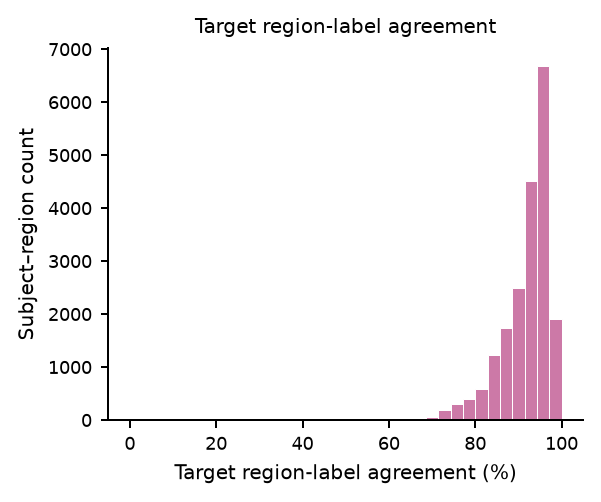

Saved: /mnt/newStor/paros/paros_WORK/xintong/results/fsaverage_mapping_qc/02_region_label_agreement_distribution.png (229 KB)


In [ ]:
x=region_qc.region_label_agreement_pct.dropna(); fig,ax=plt.subplots(figsize=(WIDTH,HEIGHT)); ax.hist(x,bins=35,color=OKABE['purple'],edgecolor='white',linewidth=.4); ax.set_title('Target region-label agreement',fontsize=8,pad=6); ax.set_xlabel('Target region-label agreement (%)'); ax.set_ylabel('Subject–region count'); ax.spines[['top','right']].set_visible(False); fig.tight_layout(); save_figure(fig,'02_region_label_agreement_distribution')

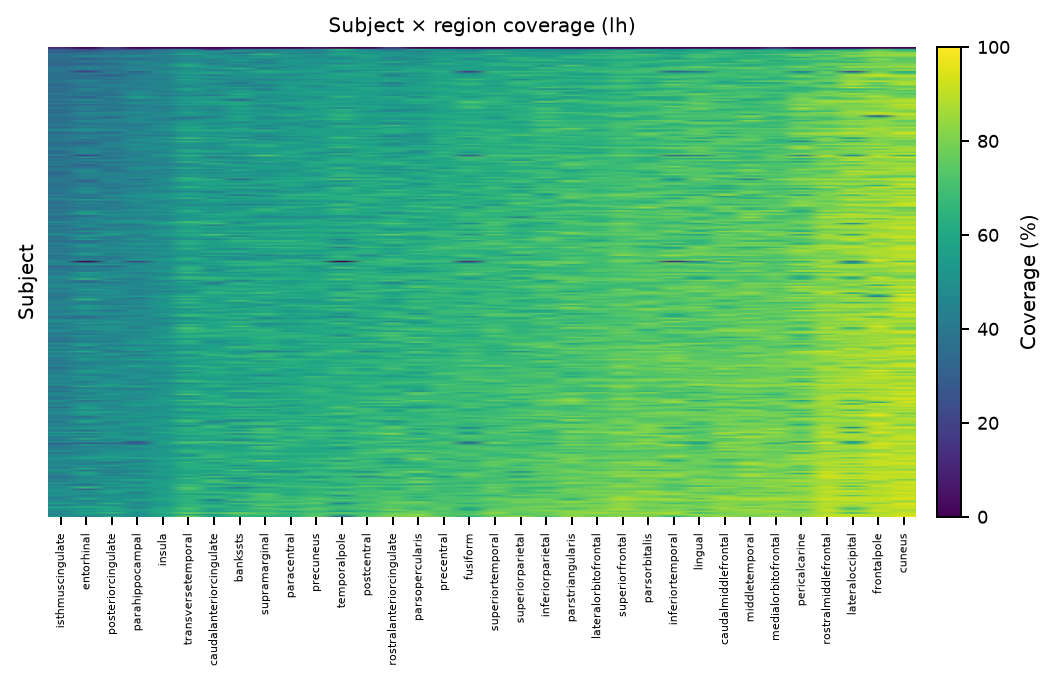

Saved: /mnt/newStor/paros/paros_WORK/xintong/results/fsaverage_mapping_qc/03_subject_region_coverage_lh.png (721 KB)


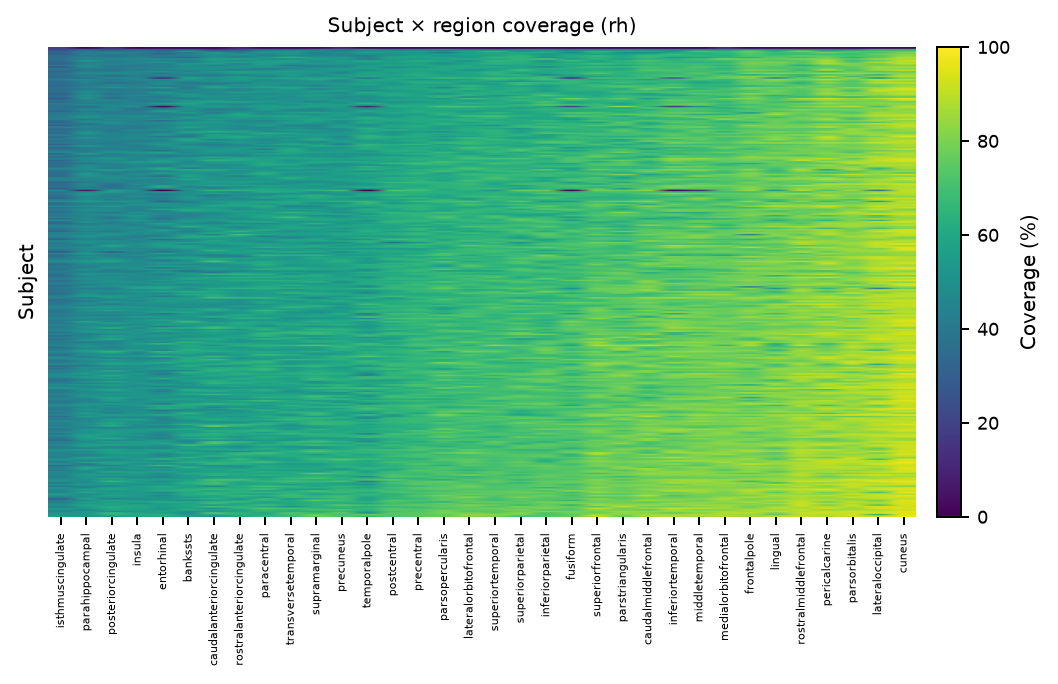

Saved: /mnt/newStor/paros/paros_WORK/xintong/results/fsaverage_mapping_qc/03_subject_region_coverage_rh.png (720 KB)


In [ ]:
for hemi in ('lh','rh'):
    plot=region_qc[region_qc.hemisphere.eq(hemi)].pivot(index='subject_id',columns='region',values='regional_coverage_valid_pct'); plot=plot.loc[plot.median(axis=1).sort_values().index,plot.median(axis=0).sort_values().index]; fig,ax=plt.subplots(figsize=(7.5,4.5)); im=ax.imshow(plot.to_numpy(),aspect='auto',cmap='viridis',vmin=0,vmax=100); ax.set_title(f'Subject × region coverage ({hemi})',fontsize=8,pad=6); ax.set_ylabel('Subject'); ax.set_xlabel(''); ax.set_xticks(range(len(plot.columns))); ax.set_xticklabels(plot.columns,rotation=90,fontsize=4.5); ax.set_yticks([]); cb=fig.colorbar(im,ax=ax,pad=.02); cb.set_label('Coverage (%)',fontsize=8); cb.ax.tick_params(labelsize=7); ax.spines[:].set_visible(False); fig.subplots_adjust(bottom=.30,top=.88); save_figure(fig,f'03_subject_region_coverage_{hemi}')
    

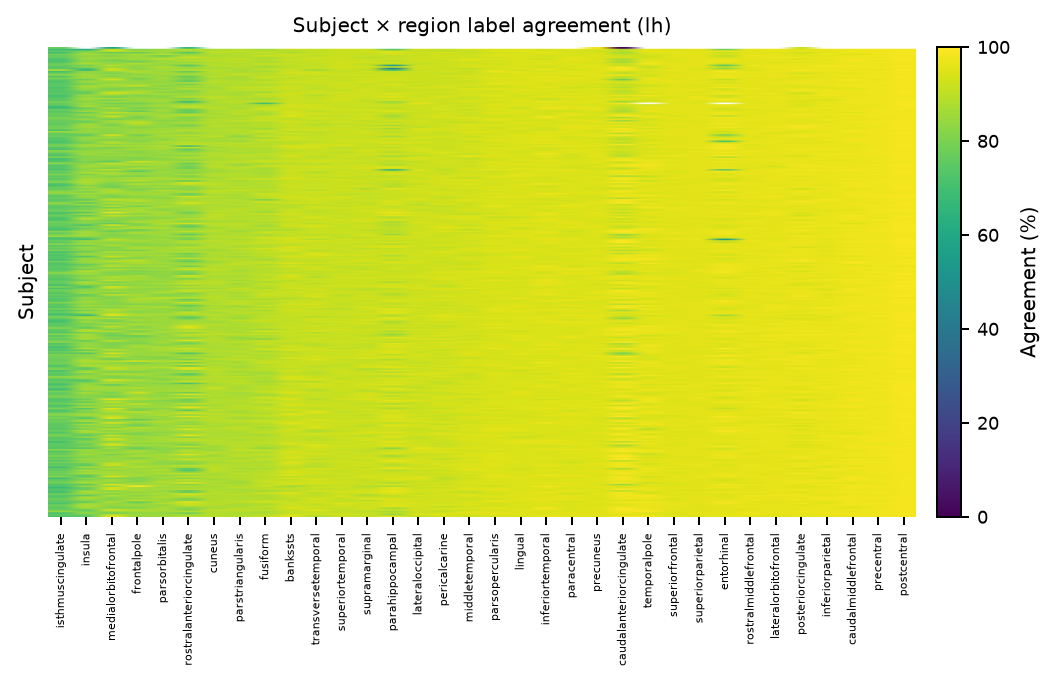

Saved: /mnt/newStor/paros/paros_WORK/xintong/results/fsaverage_mapping_qc/04_subject_region_label_agreement_lh.png (715 KB)


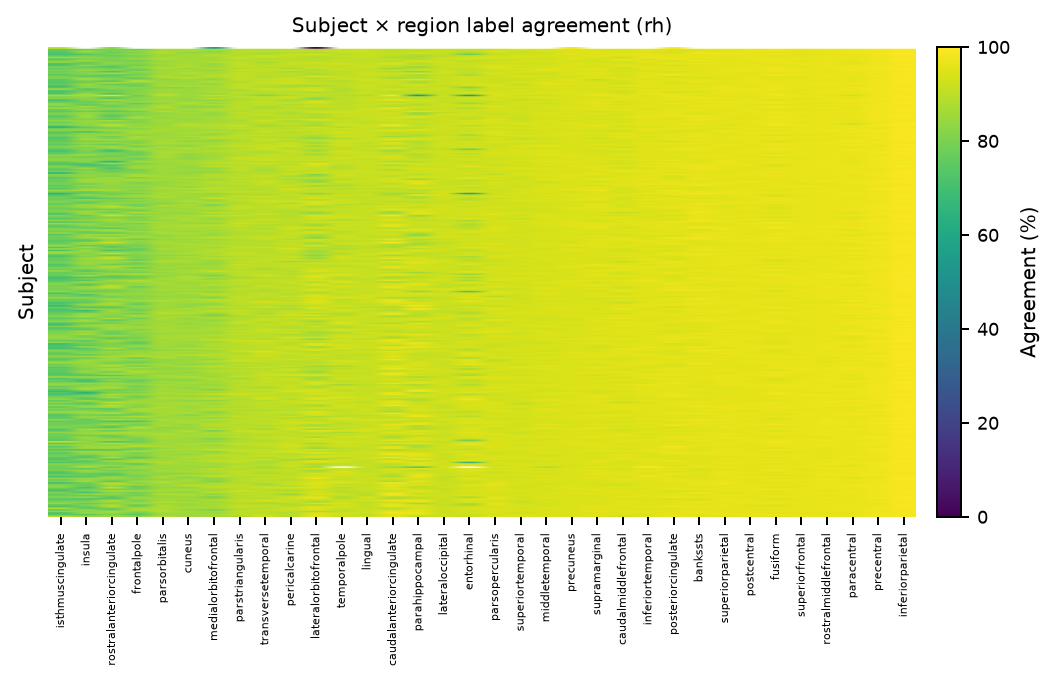

Saved: /mnt/newStor/paros/paros_WORK/xintong/results/fsaverage_mapping_qc/04_subject_region_label_agreement_rh.png (697 KB)


In [ ]:
for hemi in ('lh','rh'):
    plot=region_qc[region_qc.hemisphere.eq(hemi)].pivot(index='subject_id',columns='region',values='region_label_agreement_pct'); plot=plot.loc[plot.median(axis=1).sort_values().index,plot.median(axis=0).sort_values().index]; fig,ax=plt.subplots(figsize=(7.5,4.5)); im=ax.imshow(plot.to_numpy(),aspect='auto',cmap='viridis',vmin=0,vmax=100); ax.set_title(f'Subject × region label agreement ({hemi})',fontsize=8,pad=6); ax.set_ylabel('Subject'); ax.set_xlabel(''); ax.set_xticks(range(len(plot.columns))); ax.set_xticklabels(plot.columns,rotation=90,fontsize=4.5); ax.set_yticks([]); cb=fig.colorbar(im,ax=ax,pad=.02); cb.set_label('Agreement (%)',fontsize=8); cb.ax.tick_params(labelsize=7); ax.spines[:].set_visible(False); fig.subplots_adjust(bottom=.30,top=.88); save_figure(fig,f'04_subject_region_label_agreement_{hemi}')
    

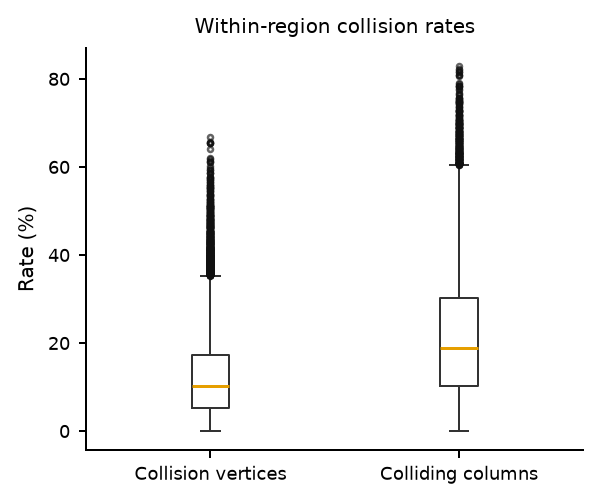

Saved: /mnt/newStor/paros/paros_WORK/xintong/results/fsaverage_mapping_qc/05_collision_rates.png (207 KB)


In [ ]:
fig,ax=plt.subplots(figsize=(WIDTH,HEIGHT)); vals=[region_qc.collision_vertex_rate_pct.dropna(),region_qc.colliding_column_rate_pct.dropna()]; ax.boxplot(vals,tick_labels=['Collision vertices','Colliding columns'],showfliers=True,patch_artist=False,boxprops={'color':'#333333','linewidth':.8},medianprops={'color':OKABE['orange'],'linewidth':1.2},whiskerprops={'color':'#333333','linewidth':.8},capprops={'color':'#333333','linewidth':.8},flierprops={'marker':'o','markersize':2,'markerfacecolor':'none','markeredgecolor':'#111111','alpha':.65}); ax.set_title('Within-region collision rates',fontsize=8,pad=6); ax.set_ylabel('Rate (%)'); ax.spines[['top','right']].set_visible(False); fig.tight_layout(); save_figure(fig,'05_collision_rates')

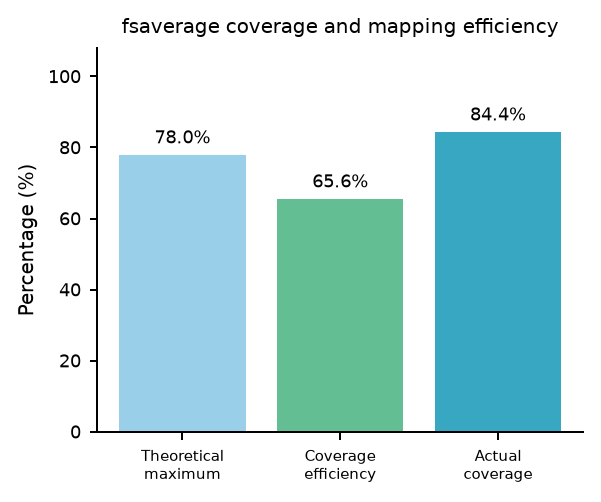

Saved: /mnt/newStor/paros/paros_WORK/xintong/results/fsaverage_mapping_qc/06_coverage_ceiling_and_efficiency.png (241 KB)


In [ ]:
values=np.array([region_qc.theoretical_max_coverage_after_cleaning_pct.median(),region_qc.regional_coverage_valid_pct.median(),region_qc.coverage_efficiency_after_cleaning_pct.median()])
fig,ax=plt.subplots(figsize=(WIDTH,HEIGHT)); bars=ax.bar(np.arange(3),values,color=['#8ecae6','#52b788','#219ebc'],alpha=.9)
ax.set_title('fsaverage coverage and mapping efficiency',fontsize=8,pad=6); ax.set_ylabel('Percentage (%)'); ax.set_ylim(0,108); ax.set_xticks(np.arange(3)); ax.set_xticklabels(['Theoretical\nmaximum','Coverage\nefficiency','Actual\ncoverage'],fontsize=6); ax.spines[['top','right']].set_visible(False)
for bar,value in zip(bars,values): ax.text(bar.get_x()+bar.get_width()/2,value+2,f'{value:.1f}%',ha='center',va='bottom',fontsize=7)
fig.tight_layout(); save_figure(fig,'06_coverage_ceiling_and_efficiency')